In [1]:
import torch
import pyarrow
import numpy as np
import torch.nn as nn

from torch.utils.data import DataLoader
from datasets import load_dataset, DatasetDict
from sklearn.feature_extraction.text import CountVectorizer

c:\Users\keert\OneDrive\Documents\Keerthi_documents\Aarhus\Studies related\Sem1\Deep Learning\Project\dl_seq_modeling\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [12]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [13]:
# Get the dataset and split it into train, test, and validation sets
dataset = load_dataset("fschlatt/trump-tweets")
train_testvalid = dataset["train"].train_test_split(test_size=0.2)
test_valid = train_testvalid['test'].train_test_split(test_size=0.5)

data = DatasetDict({
    'train': train_testvalid['train'],
    'test': test_valid['test'],
    'valid': test_valid['train']
})

In [14]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'is_retweet', 'is_deleted', 'device', 'favorites', 'retweets', 'datetime', 'is_flagged'],
        num_rows: 56571
    })
})


In [15]:
# Find the maximum length of the tweets in the dataset
max_length = max([len(tweet) for tweet in dataset['train']['text']])
print(f"Maximum length of tweets in the dataset: {max_length}")

Maximum length of tweets in the dataset: 318


In [16]:
train_texts = data['train']['text']
test_texts = data['test']['text']
valid_texts = data['valid']['text']

# Build a dictionary of unique characters to an index
unique_chars = sorted(set(''.join(train_texts)))
char_to_idx = {char: idx+2 for idx, char in enumerate(unique_chars)} # +2 because we reserve 0 for padding and 1 for unknown characters
char_to_idx['<PAD>'] = 0
char_to_idx['<UNK>'] = 1

# Convert tweets into sequences of character indices
def encode_tweets(tweets, char_to_idx, max_length=max_length):
    encoded_tweets = np.zeros((len(tweets), max_length), dtype=np.int64)
    for row, tweet in enumerate(tweets):
        for col, char in enumerate(tweet):
            if col < max_length:
                encoded_tweets[row, col] = char_to_idx.get(char, char_to_idx['<UNK>'])
    return encoded_tweets

encoded_train = encode_tweets(train_texts, char_to_idx, max_length)
encoded_test = encode_tweets(test_texts, char_to_idx, max_length)
encoded_valid = encode_tweets(valid_texts, char_to_idx, max_length)

print(f"Number of unique characters: {len(char_to_idx)}")
print(f"Example encoded tweet: {encoded_train[0]}")
print(f"Maximum tweet length in training set: {max(len(tweet) for tweet in encoded_train)}")
print(f"Maximum tweet length in test set: {max(len(tweet) for tweet in encoded_test)}")
print(f"Maximum tweet length in validation set: {max(len(tweet) for tweet in encoded_valid)}")

Number of unique characters: 696
Example encoded tweet: [ 5  5  5 33 68 65 87 83 79 78 63 52 84 79 67 75 29  3 37 79 78 10 84  3
 70 79 82 71 69 84 17  3  5  5 40 76 79 66 65 76  3 87 65 82 77 73 78 71
  5  5  3 67 65 78  3 65 76 83 79  3 77 69 65 78  3 69 65 82 84 72  3 73
 83  3 71 69 84 84 73 78 71  3 67 79 76 68 69 82  4  3 53 72 65 84  3 87
 65 89  3 84 72 69 89  3 67 79 86 69 82  3 66 79 84 72  3 83 73 68 69 83
  3 79 70  3 84 72 69  3 70 69 78 67 69  4  5  5  5  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  

In [17]:
# Convert the encoded data into dataloaders for training, testing, and validation
train_dataloader = DataLoader(encoded_train, batch_size=32, shuffle=True)
test_dataloader = DataLoader(encoded_test, batch_size=32, shuffle=False)
valid_dataloader = DataLoader(encoded_valid, batch_size=32, shuffle=False)

## Transformer architecture
Building the transformer architecture based on the diagram in slides:<br>
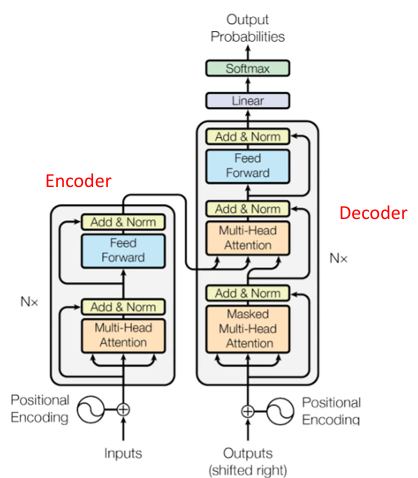

We do not need an encoder and decoder for this use case. The model just reads the tweet character by character and predicts the next character at every step. So it is the same architecture. Just does not have both encoder and decoder.

We can see it is similar to gpt-1 archi: https://towardsdatascience.com/meet-gpt-the-decoder-only-transformer-12f4a7918b36/ 

### Positional Encoding

Implemented the positional encoding as defined in the slides:<br>
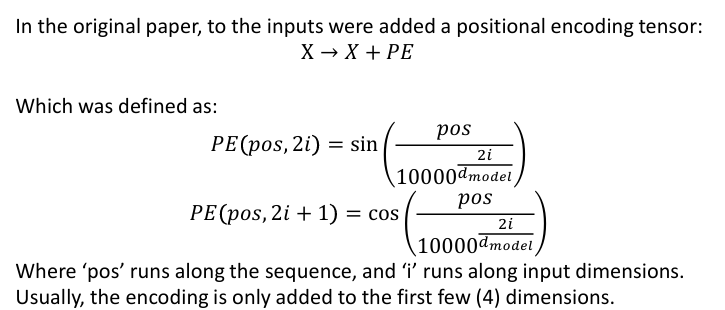

In [24]:
# Positional encoding function
class PositionalEncoding(nn.Module):
    def __init__(self, embed_size, max_len=1000):
        super(PositionalEncoding, self).__init__()
        self.embed_size = embed_size
        self.num_rows = max_len
        self.num_cols = embed_size

        pe = torch.zeros(self.num_rows, self.num_cols)
        self.build_positional_encoding(pe)
        
        # Register as buffer so model.to(device) moves it to GPU automatically
        self.register_buffer('pe', pe)

    def build_positional_encoding(self, pe):
        for pos in range(self.num_rows):
            for i in range(self.num_cols):
                if i % 2 == 0:
                    pe[pos, i] = np.sin(pos / (10000 ** (2*(i//2) / self.embed_size))) # We do i//2 because we want each pair of sine and cosine to have the same frequency, so we divide i by 2 to get the correct index for the frequency.
                else:
                    pe[pos, i] = np.cos(pos / (10000 ** (2*(i//2) / self.embed_size)))

    def forward(self, x):
        x = x + self.pe[:x.size(1), :]
        return x

In [25]:
# Test sending the input x through the positional encoding layer and testing the output shape
# Right now the input x is basically a sequences of character indices. (Right now has shape (batch_size, 318))
# 318 is the max length of any tweet in the dataset.
# In the forward pass of the encoder we would convert these character indices into embeddings, and then add the positional encoding.
# The embeddings is basically converting from (batch_size, 318) to (batch_size, 318, embed_size).
# This is so that each of the characters has embed_size number of features to learn from.
# The positional encoding is then added to this embedding, so that the model knows the position of each character in the sequence.

test_input = next(iter(test_dataloader))
embed_size = 128
pe = PositionalEncoding(embed_size=128, max_len=max_length)
embedding_test_input = nn.Embedding(len(char_to_idx), embed_size)(test_input)
pos_encoded_test_output = pe(embedding_test_input)

print(f"Input shape: {test_input.shape}")
print(f"Positional encoded output shape: {pos_encoded_test_output.shape}")

Input shape: torch.Size([32, 318])
Positional encoded output shape: torch.Size([32, 318, 128])


### Multi-head attention
- embed_size - dimensionality of the vectors used to represent each token
- num_heads - how many parallel attention mechanisms

Following the architecture from slides:
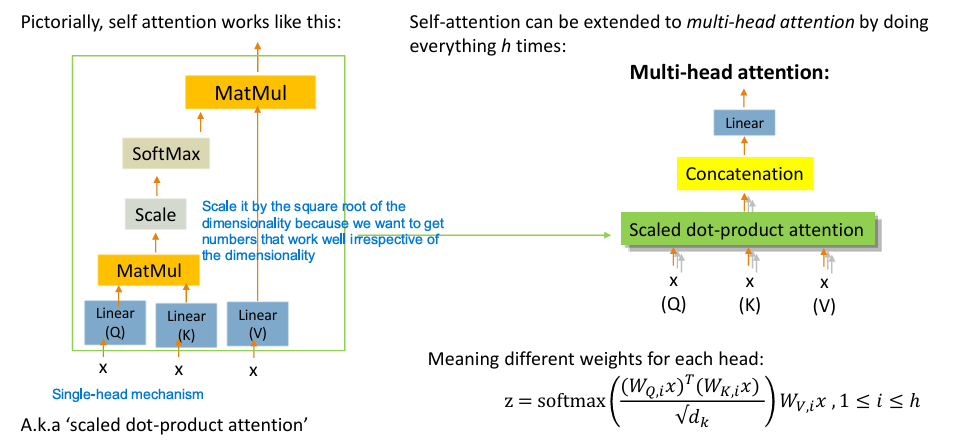

In [26]:
# Transformer model definition

# Multi head attention mechanism where we apply the formula 
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_size, num_heads):
        super(MultiHeadAttention, self).__init__()
        self.embed_size = embed_size
        self.num_heads = num_heads
        self.head_dim = embed_size // num_heads

        self.values_linear = nn.Linear(embed_size, embed_size, bias=False)
        self.keys_linear = nn.Linear(embed_size, embed_size, bias=False)
        self.queries_linear = nn.Linear(embed_size, embed_size, bias=False)

        self.fc_out = nn.Linear(num_heads * self.head_dim, embed_size)

    def self_attention(self, queries, keys, values, mask=None):
        z = torch.matmul(queries, keys.transpose(-2, -1))/np.sqrt(self.head_dim)
        if mask is not None:
            z = z.masked_fill(mask == 0, float('-inf'))
        z = torch.softmax(z, dim=-1)
        z = torch.matmul(z, values)
        return z

    def split_head(self, x):
        # We split the embedding into multiple heads.
        # Each head will still get the entire sequence of character indices but with reduced dimensions.
        # Each head will learn different features (of size head_dim) from the input sequence.
        batch_size, seq_length, embed_size = x.size()
        x = x.view(batch_size, seq_length, self.num_heads, self.head_dim)
        x = x.transpose(1, 2)  # Change shape to (batch_size, num_heads, seq_length, head_dim)
        return x

    def combine_heads(self, x):
        # Concatenate the heads together after self attention.
        batch_size, num_heads, seq_length, head_dim = x.size()
        x = x.transpose(1, 2)  # Change shape to (batch_size, seq_length, num_heads, head_dim)
        x = x.contiguous().view(batch_size, seq_length, self.embed_size)  # Change shape to (batch_size, seq_length, embed_size)
        return x

    def forward(self, queries, keys, values, mask=None):
        # Split the embedding into multiple heads
        values = self.split_head(self.values_linear(values))
        keys = self.split_head(self.keys_linear(keys))
        queries = self.split_head(self.queries_linear(queries))

        # Apply self attention
        attention = self.self_attention(queries, keys, values, mask)

        # Combine the heads back together
        out = self.combine_heads(attention)

        # Pass through a final linear layer
        out = self.fc_out(out)
        return out


In [27]:
# Test the multi-head attention mechanism with the pos_encoded_test_output
multi_head_attention = MultiHeadAttention(embed_size=128, num_heads=8)
multi_head_attention_test_output = multi_head_attention(pos_encoded_test_output, pos_encoded_test_output, pos_encoded_test_output)

print(f"Input shape: {pos_encoded_test_output.shape}")
print(f"Output shape: {multi_head_attention_test_output.shape}")

Input shape: torch.Size([32, 318, 128])
Output shape: torch.Size([32, 318, 128])


### Feed forward

Feed forward is for extracting high level features.

Implemented 2 layer neural network as descibed in the slides:<br>
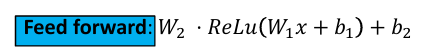

In [28]:
class FeedForward(nn.Module):
    def __init__(self, embed_size, hidden_size):
        super(FeedForward, self).__init__()
        self.fc1 = nn.Linear(embed_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, embed_size)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

### Transformer

Implementing below from slides:<br>
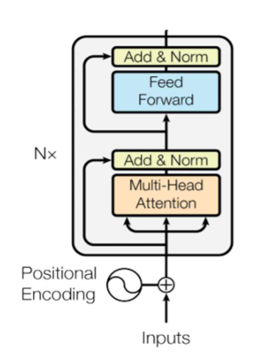

In [29]:
class Transformer(nn.Module):
    def __init__(self, embed_size, num_heads, ff_hidden_dim):
        super(Transformer, self).__init__()
        self.multi_head_attention = MultiHeadAttention(embed_size, num_heads)
        self.feed_forward = FeedForward(embed_size, ff_hidden_dim)
        self.norm1 = nn.LayerNorm(embed_size)
        self.norm2 = nn.LayerNorm(embed_size)

    def forward(self, x, mask=None):
        attention = self.multi_head_attention(x, x, x, mask)
        x = self.norm1(attention + x)
        ff_output = self.feed_forward(x)
        x = self.norm2(ff_output + x)
        return x

### Final model

In [30]:
class TweetLanguageModel(nn.Module):
    def __init__(self, vocab_size, embed_size, num_heads, ff_hidden_dim, num_layers, max_len=320):
        super(TweetLanguageModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size)
        self.pos_encoding = PositionalEncoding(embed_size, max_len)

        # Multiple layers of the transformer
        self.layers = nn.ModuleList([
            Transformer(embed_size, num_heads, ff_hidden_dim)
            for _ in range(num_layers)
        ])

        self.fc_out = nn.Linear(embed_size, vocab_size)

    def create_mask(self, seq_length):
        # This creates a lower triangluar matrix with 1s so that future positions are not seen by the model.
        # We do unsqueeze to match the dimensions of x
        return torch.tril(torch.ones((seq_length, seq_length), device=device)).unsqueeze(0).unsqueeze(0)

    def forward(self, x):
        mask = self.create_mask(x.size(1))
        x = self.pos_encoding(self.embedding(x))
        for layer in self.layers:
            x = layer(x, mask=mask)
        logits = self.fc_out(x)
        return logits

### Training the model

In [31]:
# Initialize the model, loss function, and optimizer
vocab_size = len(char_to_idx)
model = TweetLanguageModel(
    vocab_size=vocab_size,
    embed_size=128,
    num_heads=8,
    ff_hidden_dim=512,
    num_layers=4,
    max_len=320
).to(device)

# ignore_index=0 ensures <PAD> tokens don't affect the loss
criterion = nn.CrossEntropyLoss(ignore_index=0)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

# Training & Validation Loop
epochs = 1

for epoch in range(epochs):
    # Training
    model.train()
    total_train_loss = 0.0

    for batch in train_dataloader:
        batch = batch.to(device)
        # Slice input (0..316) and shifted target (1..317)
        x_batch = batch[:, :-1]
        y_batch = batch[:, 1:]

        optimizer.zero_grad()
        logits = model(x_batch)

        # Flatten batch and sequence dims for CrossEntropyLoss
        loss = criterion(logits.reshape(-1, vocab_size), y_batch.reshape(-1))
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_dataloader)

    # Validation
    model.eval()
    total_val_loss = 0.0
    with torch.no_grad():
        for batch in valid_dataloader:
            batch = batch.to(device)
            x_batch = batch[:, :-1]
            y_batch = batch[:, 1:]

            logits = model(x_batch)
            loss = criterion(logits.reshape(-1, vocab_size), y_batch.reshape(-1))
            total_val_loss += loss.item()

    avg_val_loss = total_val_loss / len(valid_dataloader)

    print(f"Epoch {epoch + 1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")


Epoch 1/1 | Train Loss: 2.4237 | Val Loss: 1.9779
